In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


df = pd.read_csv("IPL.csv", header =1)





In [ ]:
df.head()

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2008,Bangalore,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Kolkata Knight Riders,140,0,BB McCullum,M Chinnaswamy Stadium,Asad Rauf,RE Koertzen,NaN
1,2,2008,Chandigarh,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,normal,0,Chennai Super Kings,33,0,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",MR Benson,SL Shastri,NaN
2,3,2008,Delhi,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,normal,0,Delhi Daredevils,0,9,MF Maharoof,Feroz Shah Kotla,Aleem Dar,GA Pratapkumar,NaN
3,4,2008,Mumbai,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MV Boucher,Wankhede Stadium,SJ Davis,DJ Harper,NaN
4,5,2008,Kolkata,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,normal,0,Kolkata Knight Riders,0,5,DJ Hussey,Eden Gardens,BF Bowden,K Hariharan,NaN


In [ ]:
df.shape

(577, 18)

**BASIC INFORMATION**

In [ ]:
df.columns

Index(['id', 'season', 'city', 'date', 'team1', 'team2', 'toss_winner',
       'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs',
       'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2',
       'umpire3'],
      dtype='object')

In [ ]:
'winner' in df.columns

True

In [ ]:
df.loc[:, 'winner'].head()

0          Kolkata Knight Riders
1            Chennai Super Kings
2               Delhi Daredevils
3    Royal Challengers Bangalore
4          Kolkata Knight Riders
Name: winner, dtype: object

Check the size of rows and column of the dataset

In [ ]:
df.shape

(577, 18)

Now lets see how many columns have null values

In [ ]:
df.isnull().sum()

id                   0
season               0
city                 7
date                 0
team1                0
team2                0
toss_winner          0
toss_decision        0
result               0
dl_applied           0
winner               3
win_by_runs          0
win_by_wickets       0
player_of_match      3
venue                0
umpire1              0
umpire2              0
umpire3            577
dtype: int64

**Which team won the most matches**

/var/folders/75/v66m0dpd0xsclkqw7t18xzy80000gn/T/ipykernel_1025/1302858435.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y = match_wins.index , x = match_wins.values , palette = 'viridis' )


Text(0.5, 1.0, 'WINNER TEAM')

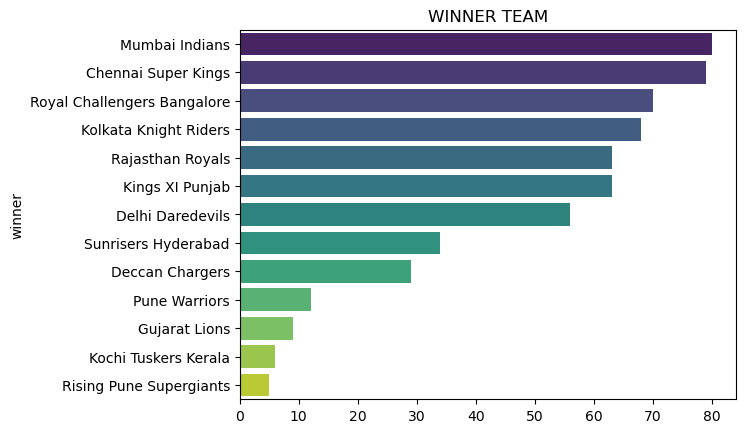

In [ ]:
match_wins = df['winner'].value_counts()
sns.barplot(y = match_wins.index , x = match_wins.values , palette = 'viridis' )
plt.title("WINNER TEAM")

Q2. Toss decision trends

/var/folders/75/v66m0dpd0xsclkqw7t18xzy80000gn/T/ipykernel_1025/3863919519.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot( x = df['toss_decision'] , palette = 'rocket')


<Axes: xlabel='toss_decision', ylabel='count'>

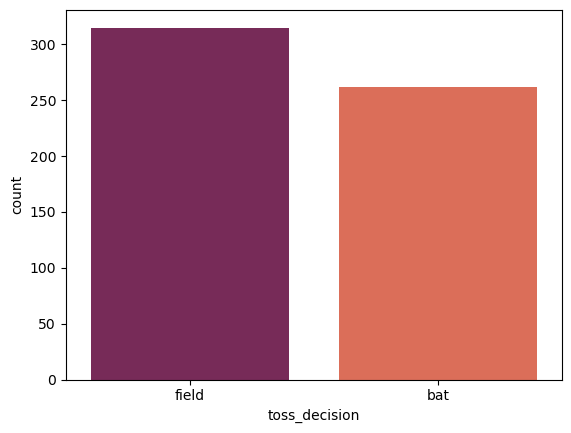

In [ ]:
sns.countplot( x = df['toss_decision'] , palette = 'rocket')

Q3.Toss winner vs match winner 

In [ ]:
count = df[df['toss_winner'] == df['winner']]['id'].count()
percentage = (count*100)/df.shape[0]
percentage

np.float64(50.433275563258235)

Q4. How do teams win?(Run vs Wicket)

Text(0, 0.5, 'Number of matches')

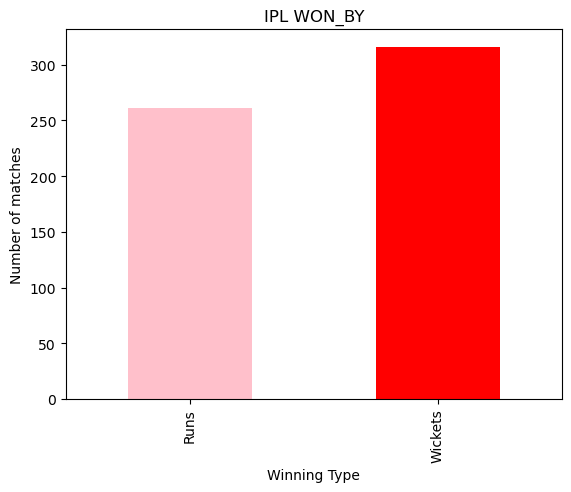

In [ ]:
df['win_type'] = df['win_by_runs'].apply(lambda x: 'Runs' if x>0 else 'Wickets' )
result = df.groupby('win_type')['id'].count()
result.plot(kind='bar' , color =['pink','red'])
plt.title("IPL WON_BY")
plt.xlabel("Winning Type")
plt.ylabel("Number of matches")

In [ ]:
df.head()

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3,win_type
0,1,2008,Bangalore,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Kolkata Knight Riders,140,0,BB McCullum,M Chinnaswamy Stadium,Asad Rauf,RE Koertzen,NaN,Runs
1,2,2008,Chandigarh,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,normal,0,Chennai Super Kings,33,0,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",MR Benson,SL Shastri,NaN,Runs
2,3,2008,Delhi,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,normal,0,Delhi Daredevils,0,9,MF Maharoof,Feroz Shah Kotla,Aleem Dar,GA Pratapkumar,NaN,Wickets
3,4,2008,Mumbai,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MV Boucher,Wankhede Stadium,SJ Davis,DJ Harper,NaN,Wickets
4,5,2008,Kolkata,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,normal,0,Kolkata Knight Riders,0,5,DJ Hussey,Eden Gardens,BF Bowden,K Hariharan,NaN,Wickets


Q5. Key "Player of the match" Awards

/var/folders/75/v66m0dpd0xsclkqw7t18xzy80000gn/T/ipykernel_1025/603852551.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=count.head(5).index , x = count.head(5).values , palette = 'magma')


<Axes: ylabel='player_of_match'>

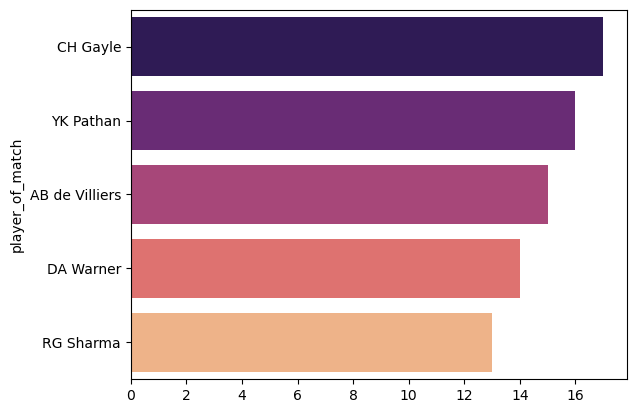

In [ ]:
count = df['player_of_match'].value_counts()
count.head(5)
sns.barplot(y=count.head(5).index , x = count.head(5).values , palette = 'magma')


In [ ]:
df.head()

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3,win_type
0,1,2008,Bangalore,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Kolkata Knight Riders,140,0,BB McCullum,M Chinnaswamy Stadium,Asad Rauf,RE Koertzen,NaN,Runs
1,2,2008,Chandigarh,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,normal,0,Chennai Super Kings,33,0,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",MR Benson,SL Shastri,NaN,Runs
2,3,2008,Delhi,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,normal,0,Delhi Daredevils,0,9,MF Maharoof,Feroz Shah Kotla,Aleem Dar,GA Pratapkumar,NaN,Wickets
3,4,2008,Mumbai,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MV Boucher,Wankhede Stadium,SJ Davis,DJ Harper,NaN,Wickets
4,5,2008,Kolkata,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,normal,0,Kolkata Knight Riders,0,5,DJ Hussey,Eden Gardens,BF Bowden,K Hariharan,NaN,Wickets


Q6. Most matches played by venue

In [ ]:
venue_count = df['venue'].value_counts()
venue_count.head(5)

venue
M Chinnaswamy Stadium              58
Eden Gardens                       54
Feroz Shah Kotla                   53
Wankhede Stadium                   49
MA Chidambaram Stadium, Chepauk    48
Name: count, dtype: int64

/var/folders/75/v66m0dpd0xsclkqw7t18xzy80000gn/T/ipykernel_1025/1890766679.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y = venue_count.head(5).index, x = venue_count.head(5).values , palette='rocket')


<Axes: ylabel='venue'>

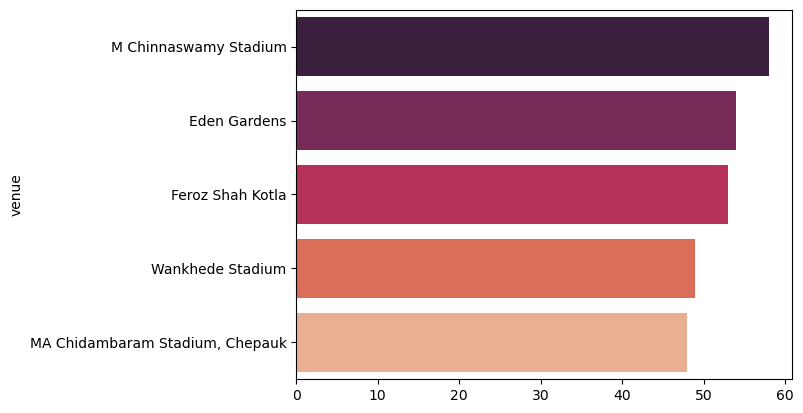

In [ ]:
sns.barplot(y = venue_count.head(5).index, x = venue_count.head(5).values , palette='rocket')

    Q7.Which stadium saw the highest number of chases?

In [ ]:
chases = df[df['win_by_wickets']>0]
chase_count = chases['venue'].value_counts()
chase_count.head(5)

venue
Eden Gardens                                 32
M Chinnaswamy Stadium                        31
Feroz Shah Kotla                             28
Rajiv Gandhi International Stadium, Uppal    26
Wankhede Stadium                             24
Name: count, dtype: int64

/var/folders/75/v66m0dpd0xsclkqw7t18xzy80000gn/T/ipykernel_1025/3476076621.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y = chase_count.head(5).index , x = chase_count.head(5).values , palette = 'magma')


<Axes: ylabel='venue'>

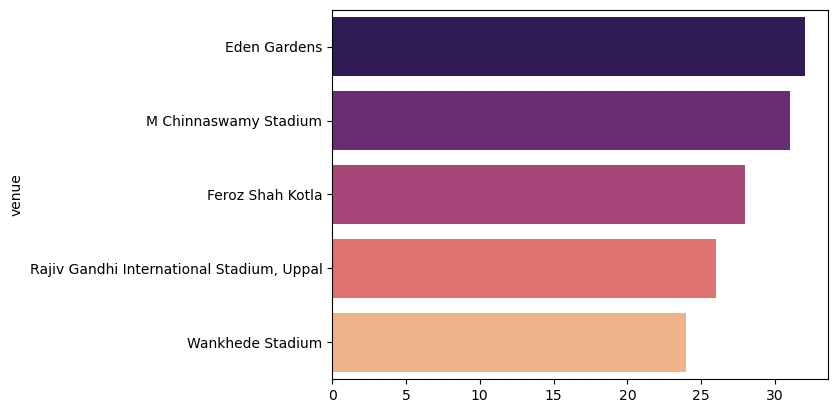

In [ ]:
sns.barplot(y = chase_count.head(5).index , x = chase_count.head(5).values , palette = 'magma')

Q8.Most frequent team vs team matchup

In [ ]:
df['matchup'] = df.apply(lambda x: 'vs'.join(sorted([x['team1'], x['team2']])
),axis=1)

In [ ]:
matchups = df['matchup'].value_counts()
matchups.head(5)

matchup
Chennai Super KingsvsMumbai Indians                   22
Mumbai IndiansvsRoyal Challengers Bangalore           19
Kings XI PunjabvsKolkata Knight Riders                19
Chennai Super KingsvsRoyal Challengers Bangalore      19
Kolkata Knight RidersvsRoyal Challengers Bangalore    18
Name: count, dtype: int64

/var/folders/75/v66m0dpd0xsclkqw7t18xzy80000gn/T/ipykernel_1025/664891480.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y = matchups.head(5).index , x = matchups.head(5).values , palette = 'rainbow')


<Axes: ylabel='matchup'>

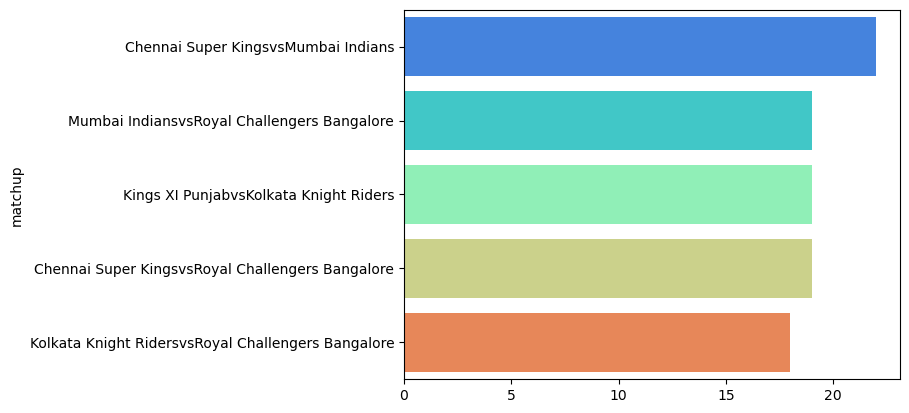

In [ ]:
sns.barplot(y = matchups.head(5).index , x = matchups.head(5).values , palette = 'rainbow')

**JUPYTER NOTEBOOK STRUCTURE**
1.Import Libraries
2.Load Dataset
3.Data Cleaning
4.Exploratry Data Anaylsis
5.Conclusion

**CONCLUSION**
-Mumbai Indians won the highest number of matches
-Chris Gayle received the highest number of Player of the Match awards.
-M Chinnaswamy Stadium hosted the maximum number of IPL matches.
-Eden Gardens witnessed the highest number of successful run chases.
-CSK vs MI was the most frequent IPL matchup.
-Winning the toss did not always result in winning the match.
-Some venues showed a clear advantage for teams batting second.